# Chapter 09 제출 답안 — 회귀 분석으로 숫자 예측하기

## 제출 정보
- 이름: 이성민
- GitHub ID: minilee0307-dot
- 작성·실행일: 2026-11-02
- 최종 Notebook URL: https://github.com/minilee0307-dot/llm-data-analysis-study/blob/main/chapter09/chapter09.ipynb
- 실습 상태: **COMPLETE** — 전체 코드 실행과 최종 Validation을 확인했다.
- GitHub 표시·eTL 접수 상태: **COMPLETE** — 2026-11-02 GitHub 본문·저장 출력·표·그래프2개·상대 이미지 링크를 확인했고, eTL에서 **2026-11-02 14:33 (Asia/Seoul) 제출됨** 및 최종 Notebook 파일 URL 접수를 확인했다. 온라인 확인과 제출은 Codex의 도움을 받았다.

### 핵심 결과

공식 공통 데이터의 **전체 주문300건**에서 주문별 상세 금액 합계 `order_total`을 예측했다. 고유 날짜 순서로 Train244건과 Final Test56건을 나누고, Train의 날짜 단위 TimeSeriesSplit5개 Fold로 비Baseline 후보를 비교했다. CV MAE가 더 낮은 **Random Forest**를 먼저 고정한 뒤 Baseline과 함께 마지막 평가를 했다.

고정 모델의 Final Test MAE는 **458,819.92원**, RMSE548,190.45원, R²−0.1033이다. Baseline MAE443,449.65원 대비 개선율은 **−3.47%**로 더 나빴다. 최종 판단은 **현재 데이터로는 사용 보류**다. 검증 절차의 PASS와 예측 성능이 좋다는 판단은 구분했다. Test를 보고 모델이나 Feature를 바꾸지 않았다.

### 자료·실행·공개 범위

2026-11-02 확인한 [eTL 과제](https://myetl.snu.ac.kr/courses/310975/assignments/388981)와 공식 커밋 `6105f42bd8294cb364dde6dcc2fee71c32e14794`의 [회귀 Notebook](https://github.com/GilbertMoon/llm-data-analysis-course/blob/6105f42bd8294cb364dde6dcc2fee71c32e14794/notebooks/ch09_regression_analysis.ipynb), [가이드](https://github.com/GilbertMoon/llm-data-analysis-course/blob/6105f42bd8294cb364dde6dcc2fee71c32e14794/practice/chapter09/chapter09.md), [답안 양식](https://github.com/GilbertMoon/llm-data-analysis-course/blob/6105f42bd8294cb364dde6dcc2fee71c32e14794/practice/chapter09/templates/chapter09_assignment.md)을 기준으로 작성했다. 공식 Notebook의 흐름을 바탕으로 저장소의 입력 경로와 공개 출력, 날짜 단위 CV 검증을 조정했다.

Chapter05~08에서 사용한 오류 탐지용 데이터와 섞지 않도록 공식 공통 Raw4개를 고정 URL·SHA-256으로 확인하고 `data/ch09/raw`, `data/ch09/processed`에 따로 보관했다. 기존 raw/clean8개는 변경하지 않았다. 이 과제는 χ-separation 뇌지도 프로젝트와 별개다.

코드 작성·실행·독립 검토·문장 정리에 Codex의 도움을 받았다. 학생이 별도로 손으로 검산하거나 모든 코드를 이미 이해했다고 주장하지 않는다. 저장된 표·검증 결과·그래프가 Evidence다. 내부 ID 파일은 생성하되 Git에서 제외하고 공개 표에는 순위 라벨만 남겼다.

## 1. 예측 문제와 시점 정의

- **Target**: `order_total = 같은 order_id의 line_total 합계`, `line_total = quantity × unit_price`.
- **예측 단위**: 주문1건. 취소·환불을 포함한 전체300주문이며 completed만의 금액 분석이 아니다.
- **예측 시점**: 고객 프로필·예정 결제수단·당일 달력 정보가 주어졌지만 장바구니 상세 수량·단가는 아직 조회하지 않은 교육용 시점.
- **알 수 있다고 가정한 정보**: 주문 월·요일, 나이·성별·도시, 예정 결제수단.
- **알 수 없는 정보**: 주문 상세·수량·거래단가·합계와 최종 주문 상태.

### 나의 해석과 판단

상세 금액을 이미 알고 예측하는 문제와 구분하려고 이 시점을 선택했다. 예정 결제수단의 실제 수집 시점과 프로필의 과거 snapshot은 확인되지 않았다. 따라서 실제 서비스에서도 같은 정보가 당시 있었다고 단정하지 않는다. 예측 대상도 기록된 상세 합계이며 실제 결제액·순매출·이익은 아니다.

In [1]:
from pathlib import Path
import sys, hashlib, subprocess, json
import numpy as np
import pandas as pd
import sklearn, scipy, joblib, matplotlib
matplotlib.use('Agg')
from IPython.display import display, Image
CURRENT=Path.cwd()
PROJECT_ROOT=next((p for p in [CURRENT,*CURRENT.parents] if (p/'scripts/prepare_ch09_data.py').is_file() and (p/'data/raw').is_dir()),None)
assert PROJECT_ROOT is not None
if str(PROJECT_ROOT) not in sys.path:sys.path.insert(0,str(PROJECT_ROOT))
REPORT_DIR=PROJECT_ROOT/'reports';PROCESSED_DIR=PROJECT_ROOT/'data/ch09/processed';FIGURE_DIR=PROJECT_ROOT/'chapter09/images'
pd.options.display.float_format=lambda x:f'{x:,.3f}'
old_input_hashes={str(p.relative_to(PROJECT_ROOT)):hashlib.sha256(p.read_bytes()).hexdigest() for folder in ['raw','processed'] for p in sorted((PROJECT_ROOT/'data'/folder).glob('*.csv'))}
print('실제 커널:',sys.executable)
print('Python:',sys.version.split()[0],'pandas:',pd.__version__,'NumPy:',np.__version__,'sklearn:',sklearn.__version__,'SciPy:',scipy.__version__,'joblib:',joblib.__version__)
print('재실행도 같은 sys.executable 사용; 보존할 이전 입력:',len(old_input_hashes))

실제 커널: /Users/sungmiiinn/Desktop/LLM을 활용한 빅데이터 분석/llm-data-analysis-course/.venv/bin/python
Python: 3.14.3 pandas: 3.0.5 NumPy: 2.5.3 sklearn: 1.9.0 SciPy: 1.18.1 joblib: 1.6.0
재실행도 같은 sys.executable 사용; 보존할 이전 입력: 8


## 1-1. 공식 공통 데이터 준비 — Evidence E01

`prepare_ch09_data.py`로 공통 원본4개를 준비했다. 원본150/100/300/764행에 결측·전체 중복·PK/FK 오류가 없는지 검사하고 타입과 날짜를 변환했다. 전체 데이터에서 median이나 범주 통계를 학습하지 않았다. 숫자·범주 보완은 모델 Pipeline 안에서만 수행한다. 현재 공통 입력의 결측은0이다.

In [2]:
from scripts.prepare_ch09_data import prepare_ch09_data
prepared=prepare_ch09_data()
display(prepared['input_summary'])
display(prepared['checks'])
assert prepared['checks'].status.eq('PASS').all()
schema=pd.DataFrame([{'dataset':name,'column':col,'dtype':str(frame[col].dtype),'missing':int(frame[col].isna().sum())} for name,frame in prepared['processed_data'].items() for col in frame.columns])
display(schema)

,dataset,source_url,sha256,rows,columns,status
0,customers,https://raw.githubusercontent.com/GilbertMoon/...,3b31aaefa66505f0a1820ccd89f0eac3b5e12830b71ecb...,150,6,PASS
1,products,https://raw.githubusercontent.com/GilbertMoon/...,46ff06753ade3e71011ee08dd366148dcd9c36521f1118...,100,4,PASS
2,orders,https://raw.githubusercontent.com/GilbertMoon/...,8f6e7ee39aa5ee6e229199532caa84bd9d4d30ef2abc2b...,300,5,PASS
3,order_items,https://raw.githubusercontent.com/GilbertMoon/...,a7a5c3942b0886c66cb38cc6a10fdfa68dbcde90e86425...,764,5,PASS


,check,value,expected,status
0,customers.pk_missing,0,0,PASS
1,customers.pk_duplicate,0,0,PASS
2,customers.whole_row_duplicate,0,0,PASS
3,products.pk_missing,0,0,PASS
4,products.pk_duplicate,0,0,PASS
5,products.whole_row_duplicate,0,0,PASS
6,orders.pk_missing,0,0,PASS
7,orders.pk_duplicate,0,0,PASS
8,orders.whole_row_duplicate,0,0,PASS
9,order_items.pk_missing,0,0,PASS


,dataset,column,dtype,missing
0,customers,customer_id,int64,0
1,customers,name,str,0
2,customers,gender,str,0
3,customers,age,int64,0
4,customers,city,str,0
5,customers,signup_date,datetime64[us],0
6,products,product_id,int64,0
7,products,product_name,str,0
8,products,category,str,0
9,products,price,int64,0


## 2. Feature Leakage Audit — Evidence E02

Feature는 아래6개로 고정했다. 주문 월·요일은 달력 정보, 나이·성별·도시는 시점 가정 아래의 프로필, payment_method는 예정 결제수단이다. 실제 운영에서는 각 값의 수집 시점과 이력을 먼저 확인해야 한다.

가장 위험하다고 본 것은 `line_total`, `quantity`, `unit_price`다. Target을 계산하는 재료라 직접 또는 간접적으로 정답을 알려 준다. `item_count`, `total_quantity`, `avg_unit_price`도 상세를 확인한 후 만드는 대리 변수다. 상태는 사후 정보, ID들은 식별자이므로 사용하지 않았다.

In [3]:
from src.regression import (FEATURE_COLUMNS,FORBIDDEN_FEATURES,TARGET_COLUMN,
    build_feature_audit,run_regression_analysis)
display(build_feature_audit())
overlap=sorted(set(FEATURE_COLUMNS)&FORBIDDEN_FEATURES)
print('Feature:',FEATURE_COLUMNS,'/ 금지 Feature overlap:',len(overlap))
assert len(FEATURE_COLUMNS)==6 and not overlap

,column,selected,available_at_prediction,target_ingredient,post_outcome_or_id,role,reason
0,order_month,True,True,False,False,allowed_feature,주문 접수 시 달력에서 계산하는 월(1~12)
1,order_dayofweek,True,True,False,False,allowed_feature,주문 접수 시 달력에서 계산하는 요일(월=0~일=6)
2,age,True,True,False,False,allowed_feature,접수 시 사용 가능한 고객 나이로 가정; 과거 시점 이력 없음
3,payment_method,True,True,False,False,allowed_feature,접수 초기 고객이 고른 예정 결제수단으로 가정
4,gender,True,True,False,False,allowed_feature,접수 시 고객 프로필에 이미 등록된 값으로 가정
5,city,True,True,False,False,allowed_feature,접수 시 고객 프로필 도시로 가정; 과거 변경 이력 없음
6,avg_unit_price,False,False,True,False,forbidden,주문 상세에서 만든 목표 대리 변수
7,customer_id,False,False,False,True,forbidden,고객 식별자
8,item_count,False,False,True,False,forbidden,주문 상세가 확인된 뒤 계산되는 사후 집계
9,line_total,False,False,True,False,forbidden,목표값을 구성하는 주문 상세 금액


Feature: ['order_month', 'order_dayofweek', 'age', 'payment_method', 'gender', 'city'] / 금지 Feature overlap: 0


## 3. Target 생성과 관계 검증 — Evidence E03

공통 함수는 **Target 검증 → 시간 분할 → Train CV → 선택 manifest 저장 → Final Test → 최종 Validation** 순서로 실행한다. 아래에서는 같은 실행에서 생성한 Evidence를 단계별로 확인한다. 모델 선택은 함수 안에서 Train CV만으로 결정되며 Test 지표가 선택 함수로 전달되지 않는다.

Target 재계산은 병합 결과만 다시 합산하지 않고 원본 상세 CSV를 별도로 읽어 Decimal 수량×단가로300개 개별 주문 금액과 전체 합계를 비교했다.

In [4]:
result=run_regression_analysis(processed_dir=PROCESSED_DIR,report_dir=REPORT_DIR,test_size=.2,random_state=42)
display(result['target_checks'])
assert result['target_checks'].status.eq('PASS').all()
print('모델링 주문 수:',len(result['model_data']))
print('Target 전체 합(원):',int(result['model_data'][TARGET_COLUMN].sum()))

,check,value,expected,status
0,customers_pk_missing,0,0,PASS
1,customers_pk_duplicate,0,0,PASS
2,products_pk_missing,0,0,PASS
3,products_pk_duplicate,0,0,PASS
4,orders_pk_missing,0,0,PASS
5,orders_pk_duplicate,0,0,PASS
6,order_items_pk_missing,0,0,PASS
7,order_items_pk_duplicate,0,0,PASS
8,FK_orders_customer_id,0,0,PASS
9,FK_order_items_order_id,0,0,PASS


모델링 주문 수: 300
Target 전체 합(원): 255610000


### 결과 관찰과 나의 판단

764개 상세가300개 주문 Target으로 집계되며 합계는255,610,000원이다. 원본 Decimal 계산과300개 개별 금액이 모두 같고 line_total 불일치, 상세 없는 주문, PK 결측·중복, FK 미매칭은0이다. 주문↔Target은 outer merge와 indicator를 사용한 one_to_one, 주문→고객은 many_to_one으로 검증했다. 누락이나 행 증식이 있으면 조용히 버리지 않고 중단하도록 했다.

이 합계는 전체 상태의 공통 샘플300주문이다. 이전 Chapter08의 오류 탐지용 데이터와 completed 금액134,523,000원과 비교하지 않는다.

## 4. Train / Final Test 시간 분할 — Evidence E04

고유 주문일207개의 앞165일을 Train, 뒤42일을 Final Test로 나눴다. 날짜를 기준으로80/20을 정했으므로 실제 주문 행 비율은 정확히80/20이 아니다.

In [5]:
display(result['split_summary'])
train_data=result['train_data'];test_data=result['test_data']
assert train_data.order_date.max()<test_data.order_date.min()
assert set(train_data.order_date.dt.normalize()).isdisjoint(test_data.order_date.dt.normalize())
print('Train max date < Final Test min date:',train_data.order_date.max().date(),'<',test_data.order_date.min().date())

,split,rows,ratio_pct,start_date,end_date
0,train,244,81.330,2025-07-09,2026-04-13
1,test,56,18.670,2026-04-14,2026-07-08


Train max date < Final Test min date: 2026-04-13 < 2026-04-14


### 분할 판단

Train은244건·2025-07-09~2026-04-13, Final Test는56건·2026-04-14~2026-07-08이다. 미래에 가까운 기간에 적용하는 상황을 보기 위해 시간 순서를 유지했다. 같은 달력 날짜가 양쪽에 걸리지 않는다. 동일 고객이 Train과 Test에 존재할 수 있으므로 이 결과가 신규 고객에 대한 일반화 성능까지 입증하지 않는다.

## 5. Train TimeSeriesSplit 후보 비교와 선택 고정 — Evidence E05

후보는 Mean Dummy, Linear Regression, Random Forest(나무300개·min_samples_leaf5·seed42)로 고정했다. 재현을 위해 RF의 n_jobs는1이다. 공식 행 단위 CV를 날짜 단위로 강화하여, Train의 고유 날짜에 TimeSeriesSplit5fold를 적용한 뒤 주문 행으로 연결했다. 같은 날이 한 Fold의 학습과 검증 양쪽에 들어가지 않게 했다.

숫자형 median→StandardScaler, 범주형 most_frequent→OneHotEncoder(handle_unknown='ignore')를 Pipeline 내부에서 각 Fold의 Train으로만 fit한다. 아래 audit는 실제 학습 median·scaler mean·encoder categories를 해당 Fold Train과 대조한다.

In [6]:
display(result['fold_details'])
display(result['preprocessing_audit'])
assert result['fold_details'].strict_train_before_validation.all()
assert result['preprocessing_audit'].status.eq('PASS').all()
display(result['cv_summary'])
display(result['fold_scores'])

,fold,train_rows,validation_rows,train_start,train_end,validation_start,validation_end,strict_train_before_validation
0,1,42,36,2025-07-09,2025-09-03,2025-09-04,2025-10-14,True
1,2,78,41,2025-07-09,2025-10-14,2025-10-16,2025-11-21,True
2,3,119,43,2025-07-09,2025-11-21,2025-11-22,2026-01-12,True
3,4,162,44,2025-07-09,2026-01-12,2026-01-13,2026-02-24,True
4,5,206,38,2025-07-09,2026-02-24,2026-02-25,2026-04-13,True


,model,fold,fit_rows,numeric_median_matches_train,scaler_mean_matches_train,encoder_categories_match_train,status
0,Baseline Mean,1,42,True,True,True,PASS
1,Baseline Mean,2,78,True,True,True,PASS
2,Baseline Mean,3,119,True,True,True,PASS
3,Baseline Mean,4,162,True,True,True,PASS
4,Baseline Mean,5,206,True,True,True,PASS
5,Linear Regression,1,42,True,True,True,PASS
6,Linear Regression,2,78,True,True,True,PASS
7,Linear Regression,3,119,True,True,True,PASS
8,Linear Regression,4,162,True,True,True,PASS
9,Linear Regression,5,206,True,True,True,PASS


,model,n_splits,cv_MAE_mean,cv_MAE_std,cv_R2_mean
0,Baseline Mean,5,"421,924.136","47,631.460",-0.025
1,Random Forest,5,"431,319.994","24,810.544",-0.095
2,Linear Regression,5,"455,325.127","57,645.538",-0.294


,model,fold,MAE,R2
0,Baseline Mean,1,"472,198.413",-0.028
1,Baseline Mean,2,"376,352.720",-0.013
2,Baseline Mean,3,"357,822.943",-0.070
3,Baseline Mean,4,"472,437.710",-0.014
4,Baseline Mean,5,"430,808.891",-0.001
5,Linear Regression,1,"559,338.476",-0.765
6,Linear Regression,2,"456,756.875",-0.315
7,Linear Regression,3,"384,532.857",-0.257
8,Linear Regression,4,"428,452.531",-0.004
9,Linear Regression,5,"447,544.896",-0.130


### Train CV 결과 관찰

| 모델 | CV MAE 평균(원) | Fold MAE 표준편차(원) | CV R² 평균 |
| --- | ---: | ---: | ---: |
| Baseline Mean | 421,924.14 | 47,631.46 | −0.0253 |
| Random Forest | 431,319.99 | 24,810.54 | −0.0951 |
| Linear Regression | 455,325.13 | 57,645.54 | −0.2941 |

각 Fold MAE를 단순 평균한 값으로 비교했다. 비Baseline 후보 중 평균 MAE가 낮은 **Random Forest**를 선택했다. **Baseline의 CV MAE는 RF보다도 낮았다.** 따라서 비Baseline 후보 중 선택되었다는 사실과 실용적인 개선은 다르다. RF의 Fold 변동이 작아 보여도 표준편차는5개 시기 구간의 산포이며 신뢰구간이나 미래 성능 보장은 아니다.

### Final Test 전 선택 고정

선택 규칙은 비Baseline CV MAE 최소, 동률이면 모델명 순이다. 모델명·Feature·고정 설정·CV 요약 해시를 manifest로 먼저 저장한 다음 Final Test 평가 함수를 호출한다. 아래 순서는 실제 코드의 실행 단계이며 manifest의 바이트가 평가 전후 같은지도 검사했다.

In [7]:
display(result['selection_manifest'])
display(result['selection_order'])
print('Train CV로 고정한 모델:',result['selected_model_name'])

{'stage': 'train_cv_frozen_before_final_test',
 'selected_model': 'Random Forest',
 'selection_rule': 'minimum mean CV MAE among non-baseline candidates; tie by model name',
 'selected_cv_mae': 431319.9941325888,
 'cv_summary_sha256': '049a5025213f760cfa124de223f023e7db43f729893f800a0d1e4323f889584d',
 'cv_split': 'TimeSeriesSplit on unique training dates, n_splits=5',
 'test_size_unique_dates': 0.2,
 'random_state': 42,
 'features': ['order_month',
  'order_dayofweek',
  'age',
  'payment_method',
  'gender',
  'city'],
 'fixed_candidates': {'Baseline Mean': 'DummyRegressor(strategy=mean)',
  'Linear Regression': 'LinearRegression()',
  'Random Forest': {'n_estimators': 300,
   'min_samples_leaf': 5,
   'random_state': 42,
   'n_jobs': 1}}}

,step,event
0,1,prepare target and split
1,2,train-only CV candidates
2,3,select by train CV
3,4,write frozen manifest
4,5,evaluate baseline and frozen model on final test
5,6,validate and save outputs


Train CV로 고정한 모델: Random Forest


## 6. Final Test: Baseline vs Frozen Model — Evidence E06

최종 비교는 Baseline과 고정한 RF 두 모델뿐이다. 선택하지 않은 Linear의 Test 성능을 계산해 교체 후보를 고르지 않았다. 재실행에서도 같은 선택 절차와 설정을 재현하며, 첫 Test 결과를 보고 Feature·모델·분할을 바꾸지 않았다.

In [8]:
display(result['model_comparison'])
display(result['metric_checks'])
assert len(result['model_comparison'])==2
assert result['metric_checks'].status.eq('PASS').all()

,model,selection_role,train_MAE,test_MAE,test_RMSE,test_R2,MAE_improvement_vs_baseline_pct
0,Baseline Mean,baseline,"416,266.192","443,449.649","522,189.700",-0.001,0.000
1,Random Forest,selected_by_train_cv,"326,438.478","458,819.917","548,190.447",-0.103,-3.470


,check,actual,expected,status
0,Baseline Mean_test_MAE,"443,449.649","443,449.649",PASS
1,Baseline Mean_test_RMSE,"522,189.700","522,189.700",PASS
2,Baseline Mean_test_R2,-0.001,-0.001,PASS
3,Random Forest_test_MAE,"458,819.917","458,819.917",PASS
4,Random Forest_test_RMSE,"548,190.447","548,190.447",PASS
5,Random Forest_test_R2,-0.103,-0.103,PASS
6,baseline_equals_train_mean,"855,295.082","855,295.082",PASS
7,MAE_improvement_pct,-3.470,-3.470,PASS


### 결과 관찰

Baseline의 Train MAE416,266.19원, Test MAE443,449.65원·RMSE522,189.70원·R²−0.0011이다. RF의 Train MAE326,438.48원, Test MAE458,819.92원·RMSE548,190.45원·R²−0.1033이다. RF의 학습 오차가 작아도 Test에서 더 낫지 않았다. Baseline 대비 MAE 개선율은−3.47%다.

### 나의 해석과 판단

- **MAE**: RF는 Test 주문의 실제 금액과 평균적으로458,819.92원만큼 차이 났다. 모든 개별 예측이 이 범위 안이라는 뜻은 아니다.
- **RMSE**:548,190.45원으로 MAE보다 커 큰 오차 사례의 영향을 더 받았다.
- **R²**: `1−오차제곱합/실제값의 Test 평균 중심 제곱합`이다. 음수는 이 Test의 실제값 평균을 상수로 쓴 기준보다 제곱오차가 크다는 뜻이다. 평균 예측 기준은 지표를 해석하는 비교값이며 Test 평균을 학습에 사용한 것이 아니다. Dummy는 **Train 평균855,295.08원**을 예측하므로 Test R²가 반드시0일 필요는 없다.
- **개선율**: `(Baseline MAE−RF MAE)/Baseline MAE×100=−3.47%`이므로 약3.47% 악화다.

### 업무·분석적 의미

현재 허용한 정보와 데이터에서는 복잡한 모델이 단순 평균보다 추가 가치를 보이지 않았다. 수십만 원의 평균 오차와 백만 원 이상의 대표 오차를 주문별 견적·예산의 확정값으로 사용하기 어렵다. 모델 복잡성보다 예측 시점에 유효한 정보와 업무상 허용 오차를 먼저 점검할 필요가 있다.

## 7. 대표 오차 사례와 그래프

잔차는 **실제값−예측값**이다. 양수는 과소예측, 음수는 과대예측이다. 아래 공개 표는 큰 절대오차 순위 라벨만 사용하며 원본ID와 개별 주문 날짜를 출력하지 않는다.

In [9]:
public_predictions=result['public_predictions']
display(public_predictions.head(3))

,case_label,actual_order_total,predicted_order_total,residual,abs_error,model
0,Error rank 01,1877000,"605,528.716","1,271,471.284","1,271,471.284",Random Forest
1,Error rank 02,1767000,"756,889.655","1,010,110.345","1,010,110.345",Random Forest
2,Error rank 03,1863000,"861,784.708","1,001,215.292","1,001,215.292",Random Forest


### 사례 1. Error rank 01
- 실제1,877,000원, 예측605,528.72원, 잔차+1,271,471.28원, 절대오차1,271,471.28원이다.
- **관찰**: 큰 금액 주문을 과소예측했다.
- **가능한 이유 후보**: 현재 Feature로 고액 주문을 구분할 사전 신호가 부족했을 수 있다. 원인으로 확정하지 않았다.
- **추가 확인**: 실제 예측 시점에 알려진 상품군이나 고객 과거 구매 이력이 있는지와 해당 정보의 시점 유효성을 확인한다. Target 재료인 상세 수량·단가를 이번 모델에 다시 넣지 않는다.

### 사례 2. Error rank 02
- 실제1,767,000원, 예측756,889.65원, 잔차+1,010,110.35원, 절대오차1,010,110.35원이다.
- **관찰**: 이 사례도 큰 양수 잔차를 보였다.
- **가능한 이유 후보**: 비슷한 프로필·달력 Feature를 가진 주문들의 금액 편차가 클 가능성이 있다. 해당 집단의 분산을 직접 확인한 결론은 아니다.
- **추가 확인**: Train에서 유사한 Feature 집단의 Target 분포와 표본 수를 확인한다.

### 사례 3. Error rank 03
- 실제1,863,000원, 예측861,784.71원, 잔차+1,001,215.29원, 절대오차1,001,215.29원이다.
- **관찰**: 상위3사례 모두 과소예측이며 백만 원 이상 오차다. 모든 Test 오류가 과소예측이라는 뜻은 아니다.
- **가능한 이유 후보**: 시간에 따른 분포 차이나 제한된 Feature 정보가 영향을 주었을 수 있지만 이 사례만으로 구분할 수 없다.
- **추가 확인**: 더 긴 기간의 독립 데이터에서 오차 방향·Target 범위·분포 변화를 비교한다. 현재 Test를 보고 튜닝하지 않는다.

### 실제값–예측값 산점도

점1개가 Final Test 주문1건이다. 대각선은 완전 예측 `y=x`이고 두 축은 같은 범위·원 단위다. 점이 대각선 위·아래 어디에 있는지와 예측이 실제값의 넓은 범위를 따라가는지 확인한다.

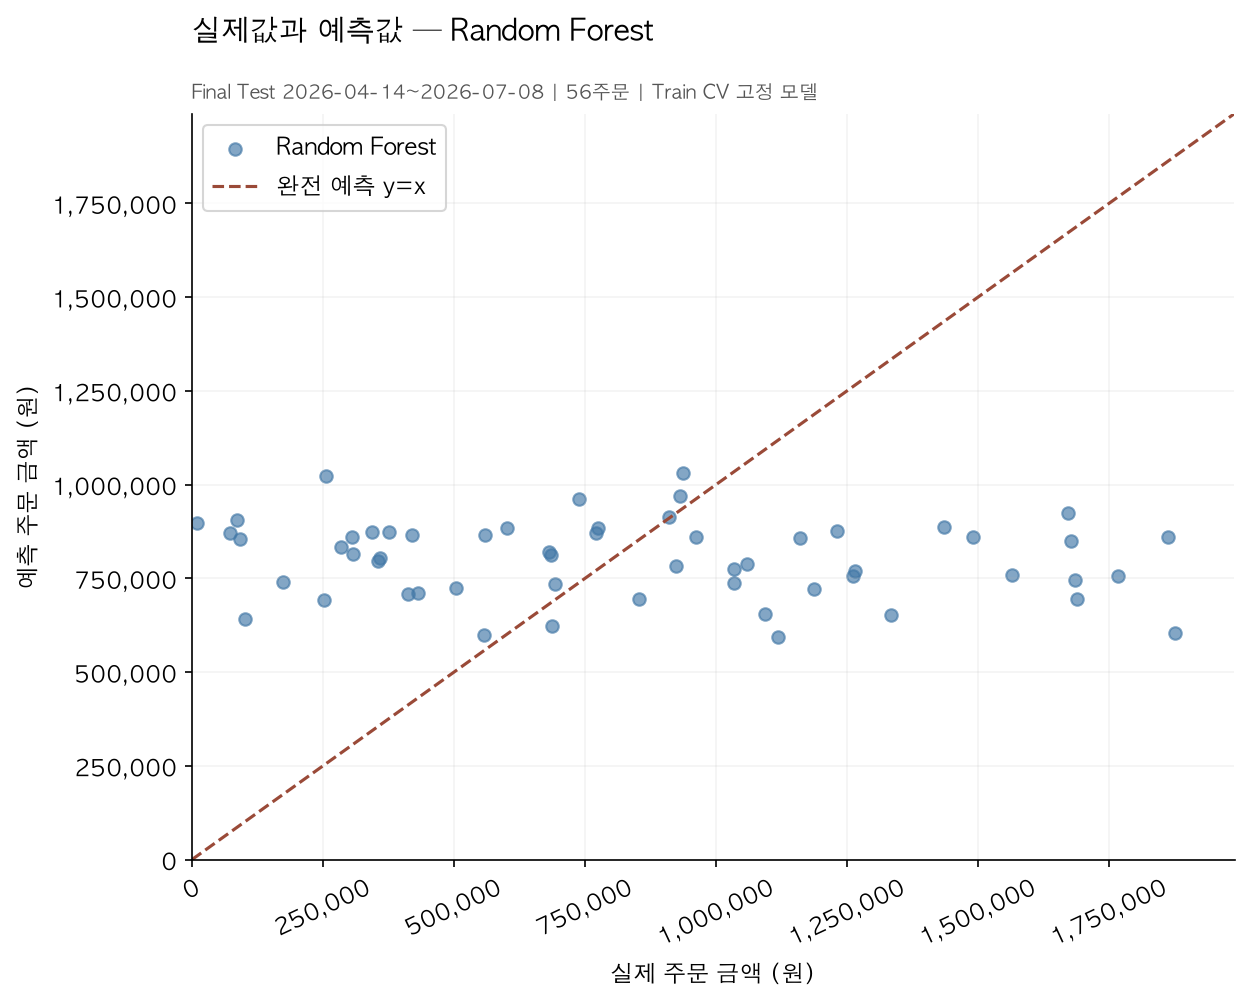

In [10]:
display(Image(filename=str(FIGURE_DIR/'graph01.png')))

실제56개 점의 x/y를 저장 예측 배열과 대조했다. 고액 실제값에 비해 낮은 예측 사례가 보이며, 이것만으로 특정 Feature의 인과효과를 알 수 없다. [산점도 이미지](images/graph01.png).

### 잔차 히스토그램

잔차의 방향과 큰 오차 분포를 보기 위해 히스토그램을 선택했다.0기준선을 표시했고 양수·음수 전체 범위를 포함했다. bin 도수와 막대 높이를 원본 잔차의 numpy.histogram 결과와 대조했다.

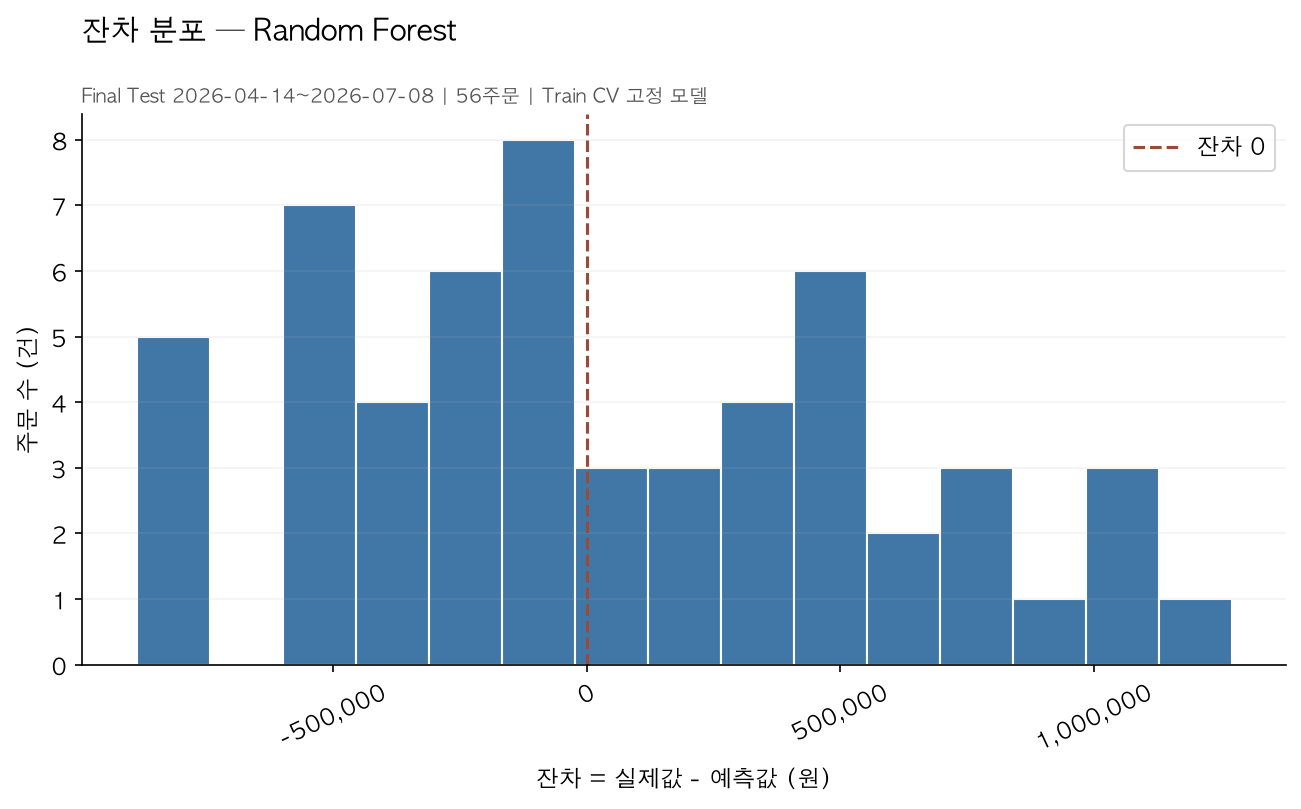

,check,value,expected,passed,status
0,scatter coordinates,56,56,True,PASS
1,identity line equal x/y,2,2,True,PASS
2,histogram count sum,56,56,True,PASS
3,zero reference line,0,0,True,PASS


In [11]:
display(Image(filename=str(FIGURE_DIR/'graph02.png')))
display(result['artist_checks'])
assert result['artist_checks'].status.eq('PASS').all()

도수 합은 Test56건이다. 잔차가0을 중심으로 한쪽 방향만 있는 것은 아니며 큰 양수 꼬리에 상위 오차 사례가 있다. 이 그림만으로 잔차의 정규성·독립성이나 발생 원인을 확정하지 않는다. [잔차 이미지](images/graph02.png).

## 8. Validation Evidence

아래는 [reports/ch09_regression_validation.csv](../reports/ch09_regression_validation.csv)의 실제 결과다. 금지 Feature overlap0, 엄격한 Train/Test 순서, Train CV 안에 선택 모델 존재, Baseline과 고정 모델 최종 비교, R²를 계산할 Test 표본 수를 포함한다. 검증된 실행 절차가 높은 예측 성능을 보장하는 것은 아니다.

In [12]:
display(result['validation'])
assert result['validation'].status.eq('PASS').all()
print('최종 Validation:',len(result['validation']),'/',len(result['validation']),'PASS')

,check,value,status
0,forbidden_feature_overlap,0,PASS
1,strict_train_before_test,True,PASS
2,selected_model_exists_in_train_cv,True,PASS
3,final_test_contains_baseline,True,PASS
4,final_test_contains_frozen_selected_model,True,PASS
5,test_rows_for_r2,56,PASS
6,target_and_relationship_checks,18,PASS
7,strict_cv_date_groups,5,PASS
8,train_only_preprocessing_audit,15,PASS
9,selected_is_minimum_train_cv_mae,Random Forest,PASS


최종 Validation: 15 / 15 PASS


**FAIL 항목**: 최종 자동 검증에는 없다. 단, 실제 프로필의 과거 시점 가정과 운영 성능까지 검증됐다는 뜻은 아니다. 현재 합성 입력에는 날짜·키·Target 문제로 제외된 주문이 없다. 모델 성능이 Baseline보다 나쁜 결과는 지우지 않았다.

## 9. Evidence와 공개 범위

필수 공개 CSV6개(split_summary, feature_audit, cv_summary, model_comparison, validation, checklist), 보고서와 그래프2개를 저장했다. Target·Fold·전처리·지표·artist 검증 및 선택 manifest도 함께 남겼다.

`ch09_regression_model_data_internal.csv`와 `ch09_regression_predictions_internal.csv`에는 원본ID가 필요한 내부 계산이 들어갈 수 있어 **실제 생성하되 Git에서 제외**한다. 원본 공통 데이터 캐시와 processed도 Git 제외이며 고정 공식 URL·SHA로 다시 준비한다. 공개 예측 표에는 `case_label, actual_order_total, predicted_order_total, residual, abs_error, model`만 사용한다. 순위 라벨은 실행·모델에 따라 달라질 수 있는 오류 순위이지 영구 고객 ID가 아니다.

In [13]:
forbidden_public={'order_id','customer_id','product_id','name','email','phone','address','order_date'}
assert not forbidden_public.intersection(public_predictions.columns)
saved_public=pd.read_csv(REPORT_DIR/'ch09_regression_public_predictions.csv')
assert not forbidden_public.intersection(saved_public.columns)
assert len(saved_public)==len(test_data)
assert saved_public.case_label.str.fullmatch(r'Error rank [0-9]{2,}').all()
print('공개 예측 컬럼:',saved_public.columns.tolist())
for name in ['ch09_regression_model_data_internal.csv','ch09_regression_predictions_internal.csv']:
    path=REPORT_DIR/name
    assert path.exists() and path.stat().st_size>0
    print('Internal 생성 확인:',name)
    if (PROJECT_ROOT/'.git').exists():
        ignored=subprocess.run(['git','check-ignore',str(path.relative_to(PROJECT_ROOT))],cwd=PROJECT_ROOT,capture_output=True,text=True)
        assert ignored.returncode==0
        print('Git 제외: PASS')
display(result['checklist'])

공개 예측 컬럼: ['case_label', 'actual_order_total', 'predicted_order_total', 'residual', 'abs_error', 'model']
Internal 생성 확인: ch09_regression_model_data_internal.csv
Git 제외: PASS
Internal 생성 확인: ch09_regression_predictions_internal.csv
Git 제외: PASS


,check_item,status,evidence
0,예측 시점·프로필 정보 가정 명시,PASS,report
1,목표값과 계산 재료를 Feature에서 제외,PASS,feature_audit
2,사후 주문 상태와 식별자를 Feature에서 제외,PASS,feature_audit
3,각 Train fold에서만 전처리 fit,PASS,preprocessing_audit
4,Train/Final Test 날짜 엄격 분리,PASS,split_summary
5,CV Train/Validation 날짜 엄격 분리,PASS,cv_folds
6,Train CV 최저 MAE로 비Baseline 모델 고정,PASS,selection_manifest
7,선택 파일을 먼저 저장한 뒤 Final Test 평가,PASS,selection_order
8,Final Test는 Baseline과 고정모델만 비교,PASS,model_comparison
9,MAE·RMSE·R²와 낮은 성능도 보고,PASS,model_comparison


## 10. LLM 활용과 실제 검증

- 목적: Feature 시점·누수, Train CV와 Final Test 순서, 지표와 오차 해석 검토.
- Safe Context: 합성 데이터 행 수·분할 요약·Feature 및 검증 계획만 제공. 고객 원본 행·ID·연락처 미제공.
- Prompt 요약: 사전 시점 가정, Pipeline, 날짜 단위 CV, 선택 고정, 오차의 사실과 가설을 검토하고 확인하지 않은 성능을 만들지 말라고 요청했다.
- 실제 요청 요약과 응답: [LLM 검토 기록](llm_review.md).

| 실제 제안 | 판단 | 실행·검토 근거 |
| --- | --- | --- |
| Target·관계·Pipeline·날짜 분할·선택 고정 | 사용 | 원본 개별 Target300개 대조, 5Fold×3모델의 전처리 검사15개, 선택 manifest 선저장 |
| Feature의 시점 가정 | 수정 후 사용 | 예정 결제수단 수집 시점과 과거 프로필 이력 미검증을 한계로 명시 |
| CV 표준편차와 Baseline도 함께 확인 | 사용 | RF가 비Baseline 중 최저이지만 Baseline CV보다 나쁜 실제 표를 기록 |
| R²의 Test 평균과 Dummy Train 평균 구분 | 수정 후 사용 | 지표 재계산8개와 평균855,295.08원 기준을 확인 |
| 오차의 사실·원인 가설 구분 | 사용 | 공개 상위3오차 수치를 확인하고 후보 원인은 추가 확인 사항으로만 작성 |
| 실제 배포 가능성·원인 확정 | 보류 | Test 개선율−3.47%, 작은 합성 표본과 시점 가정 때문에 현재 사용 보류 |

LLM의 제안 자체를 검증 결과로 쓰지 않고 실제 코드와 Train CV, 고정 모델의 마지막 평가에 대조했다. Test 결과를 보고 새 Feature나 모델을 선택하지 않았다. 작성·실행·독립 검토에는 Codex의 도움을 받았다.

## 11. 전체 재실행 확인

새 프로세스로 입력 준비와 회귀 스크립트를 순서대로 실행한다. 이 재실행은 고정한 절차의 재현 확인이며, 같은 Test로 새로운 설정을 선택하는 과정이 아니다.

In [14]:
def artifact_hashes():
    paths=sorted(REPORT_DIR.glob('ch09_*'))+sorted((REPORT_DIR/'figures').glob('ch09_*.png'))+sorted(FIGURE_DIR.glob('graph*.png'))
    return {str(p.relative_to(PROJECT_ROOT)):hashlib.sha256(p.read_bytes()).hexdigest() for p in paths if p.is_file()}
before=artifact_hashes()
for script in ['scripts/prepare_ch09_data.py','scripts/run_regression_analysis.py']:
    run=subprocess.run([sys.executable,script],cwd=PROJECT_ROOT,check=True,capture_output=True,text=True)
    print(run.stdout)
after=artifact_hashes()
assert before==after,'Notebook/스크립트 산출물 해시 차이'
current_inputs={str(p.relative_to(PROJECT_ROOT)):hashlib.sha256(p.read_bytes()).hexdigest() for folder in ['raw','processed'] for p in sorted((PROJECT_ROOT/'data'/folder).glob('*.csv'))}
assert current_inputs==old_input_hashes
saved_validation=pd.read_csv(REPORT_DIR/'ch09_regression_validation.csv')
assert saved_validation.status.eq('PASS').all()
print('두 스크립트 종료코드0; Notebook/스크립트 산출물 해시 일치:',len(after),'개')
print('이전 raw/clean CSV 보존:',len(current_inputs),'개; 저장 Validation 재읽기: PASS')

Chapter09 공통 원본 준비 완료 (기존 Chapter05~08 입력 보존)
    dataset  rows  columns status
  customers   150        6   PASS
   products   100        4   PASS
     orders   300        5   PASS
order_items   764        5   PASS
                                 relationship  invalid_count status
  orders.customer_id -> customers.customer_id              0   PASS
      order_items.order_id -> orders.order_id              0   PASS
order_items.product_id -> products.product_id              0   PASS
Feature imputation before split: False; all learned preprocessing is inside Train pipelines



Chapter09 regression complete: 2026-11-02
split_summary
split  rows  ratio_pct start_date   end_date
train   244      81.33 2025-07-09 2026-04-13
 test    56      18.67 2026-04-14 2026-07-08
feature_audit
         column  selected  available_at_prediction  target_ingredient  post_outcome_or_id            role                             reason
    order_month      True                     True              False               False allowed_feature          주문 접수 시 달력에서 계산하는 월(1~12)
order_dayofweek      True                     True              False               False allowed_feature      주문 접수 시 달력에서 계산하는 요일(월=0~일=6)
            age      True                     True              False               False allowed_feature 접수 시 사용 가능한 고객 나이로 가정; 과거 시점 이력 없음
 payment_method      True                     True              False               False allowed_feature          접수 초기 고객이 고른 예정 결제수단으로 가정
         gender      True                     True              False               False 

## 12. 최종 사용 판단

- [ ] 현재 수준에서 참고용 사용 가능
- [ ] 추가 검증 후 사용 가능
- [x] **현재 데이터로는 사용 보류**

### 판단 근거
1. Train CV에서 RF MAE431,319.99원은 Linear보다 낮지만 Baseline421,924.14원보다 높았다.5개 Fold의 변동도 있고 한 번의 기간 분리만으로 안정성을 확정할 수 없다.
2. 보호한 Final Test에서 RF MAE458,819.92원·RMSE548,190.45원·R²−0.1033이며 Baseline 대비−3.47%로 개선되지 않았다.
3. 상위3개 오차는 모두 백만 원 이상 과소예측이다. 알려진 Target 재료·ID·사후 상태는 Feature에서 제외했고 엄격한 시간 순서를 지켰지만, 현재 정보와 데이터의 예측력은 부족했다.

### 업무적 위험과 데이터 한계

주문별 확정 견적·예산 결정에 쓰면 큰 차이가 생길 수 있다. 표본은 합성300주문·Test56건이며 실제 서비스의 허용 오차도 확인하지 않았다. 현재 프로필을 과거에 적용한 시점 가정과 예정 결제수단의 수집 시점을 검증하지 못했다. 양 기간에는 같은 고객도 있어 신규 고객 예측을 입증하지 않는다. 과거 프로필 이력·더 긴 기간·독립 검증 데이터가 필요하다.

### 다음 개선 우선순위
1. 실제 서비스의 예측 시점과 허용 오차를 정하고 프로필·결제수단의 당시 가용성을 확인한다.
2. 그 시점까지의 고객 과거 정보 등 새 Feature가 정답 대리 변수나 미래 정보가 아닌지 감사한다. 현재 Test로 선택하지 않고 새로운 검증 기간을 마련한다.
3. 더 긴 기간과 독립 데이터에서 같은 Baseline·시간 검증을 반복하고, 기존 고객과 신규 고객의 적용 범위를 구분한다.

## 최종 체크

- [x] 공식 공통 원본을 고정 commit·해시로 준비하고 기존 입력과 구분했다.
- [x] Target·예측 단위·시점·가용 정보와 가정을 정의했다.
- [x] 허용6개와 금지11개의 Feature Audit과 제외 이유를 작성했다.
- [x] Target·PK/FK·one_to_one/many_to_one 관계와 개별 금액을 검증했다.
- [x] Train/Final Test와 CV의 같은 날짜 중복을 막았다.
- [x] 각 Fold의 Train Pipeline으로만 전처리를 학습했다.
- [x] Dummy·Linear·RF를 Train CV로 비교한 뒤 비Baseline 모델을 먼저 고정했다.
- [x] Final Test에서는 Baseline과 고정 모델만 비교하고 낮은 성능도 기록했다.
- [x] 지표·대표 오차3건·그래프와 사용 보류 근거를 작성했다.
- [x] Validation이 모두PASS이고 Internal과 공개 결과를 구분했다.
- [x] 같은 환경에서 두 스크립트를 재실행하고 저장 산출물 해시를 비교했다.
- [x] GitHub에서 본문·실행 출력·표·그래프·상대 링크를 확인했다.
- [x] 최종 Notebook URL의 eTL 접수를 확인했다.

실습 실행과 온라인 접수를 각각 확인했다. eTL 제출물 상세정보에는 2026-11-02 오후2:33 제출됨으로 표시되며 제출 주소는 상단의 최종 Notebook 파일 URL이다. 채점 결과는 아직 없다.